# Figure 6b. AD colocalization enrichment

The unit is a distinct colocalization confidence set (CoS) in both the AD-centered and *trans*-only analyses. For each QTL class, enrichment is the fraction of AD CoS containing that class, divided by its fraction among background *trans*-only CoS; the denominator within each analysis is the union of *trans*-eGene and *trans*-eProgram CoS. These classes can overlap.

Error bars are 95% intervals from a 22-autosome leave-one-chromosome-out jackknife on the log enrichment scale. The bracket compares program and gene enrichment using the corresponding log-ratio jackknife standard error (two-sided *P* = 8.61 x 10^-10; `***` denotes *P* < 0.001). The two analyses have different selection criteria, so this is a descriptive comparison of their CoS composition.

Input: `data/Figure_6b_ad_coloc_enrichment.rds` (plot-ready counts, estimates, uncertainty and source checksums). [Editable SVG](Figure_6b.svg).

Warning message:
"package 'ggplot2' was built under R version 4.4.3"


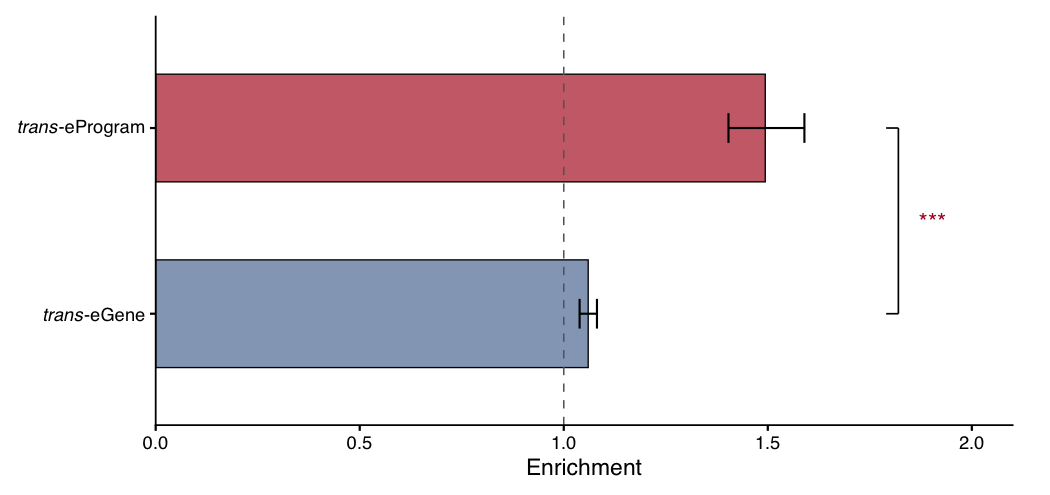

In [1]:
suppressPackageStartupMessages(library(ggplot2))
x <- readRDS("data/Figure_6b_ad_coloc_enrichment.rds")
stopifnot(identical(x$unit, "CoS"), nrow(x$bars) == 2L)
d <- x$bars
d$qtl_type <- factor(d$qtl_type, levels = c("trans-eGene", "trans-eProgram"))

p <- ggplot(d, aes(x = enrichment, y = qtl_type, fill = qtl_type)) +
  geom_col(width = 0.58, color = "black", linewidth = 0.3, alpha = 0.82) +
  geom_vline(xintercept = 1, linetype = "dashed", linewidth = 0.35,
             color = "#666666") +
  geom_errorbar(aes(xmin = ci_low, xmax = ci_high), orientation = "y",
                width = 0.16, linewidth = 0.48) +
  annotate("segment", x = 1.82, xend = 1.82, y = 1, yend = 2,
           linewidth = 0.38) +
  annotate("segment", x = 1.79, xend = 1.82, y = 1, yend = 1,
           linewidth = 0.38) +
  annotate("segment", x = 1.79, xend = 1.82, y = 2, yend = 2,
           linewidth = 0.38) +
  annotate("text", x = 1.87, y = 1.5, label = x$comparison$symbol,
           hjust = 0, vjust = 0.5, size = 4, color = "#B2182B") +
  scale_fill_manual(values = c("trans-eGene" = "#7991B1",
                               "trans-eProgram" = "#C24755"), guide = "none") +
  scale_y_discrete(labels = c("trans-eGene" = expression(italic("trans") * "-eGene"),
                              "trans-eProgram" = expression(italic("trans") * "-eProgram"))) +
  scale_x_continuous(limits = c(0, 2.1), breaks = seq(0, 2, by = 0.5),
                     labels = function(z) sprintf("%.1f", z),
                     expand = expansion(mult = c(0, 0))) +
  labs(x = "Enrichment", y = NULL) +
  coord_cartesian(clip = "off") +
  theme_classic(base_size = 11, base_family = "sans") +
  theme(axis.line = element_line(linewidth = 0.4),
        axis.text = element_text(color = "black"),
        plot.background = element_rect(fill = "white", color = NA),
        plot.margin = margin(8, 18, 8, 8))
ggsave("Figure_6b.svg", p, width = 7, height = 3.3, units = "in", device = svglite::svglite)
options(repr.plot.width = 7, repr.plot.height = 3.3, repr.plot.res = 150)
print(p)